In [1]:
%pip install -U ucimlrepo

  Using cached ucimlrepo-0.0.7-py3-none-any.whl.metadata (5.5 kB)
Using cached ucimlrepo-0.0.7-py3-none-any.whl (8.0 kB)
Note: you may need to restart the kernel to use updated packages.



# Online Shoppers Purchasing Intention Prediction

## 1. Problem Statement

The objective of this project is to build a machine learning classification system that predicts whether an online browsing session results in a purchase.

The target variable is `Revenue`:
- `True`: The session resulted in a purchase.
- `False`: The session did not result in a purchase.

## 2. Dataset Overview

The dataset contains information about user browsing behaviour, page interactions, visit timing, traffic sources, and visitor characteristics.

## 3. Initial Approach

Before building models, we will:
1. Inspect the dataset structure and data types.
2. Understand the meaning of every feature.
3. Assess data quality and missing values.
4. Explore feature distributions and relationships.
5. Design suitable preprocessing steps based on our findings.


In [2]:
import pandas as pd
import numpy as np

from ucimlrepo import fetch_ucirepo

In [3]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=468)

X_raw = dataset.data.features.copy()
y_raw = dataset.data.targets["Revenue"].copy()

df_raw = X_raw.copy()
df_raw["Revenue"] = y_raw

print("Rows:", df_raw.shape[0])
print("Input features:", X_raw.shape[1])

df_raw.info()

Rows: 12330
Input features: 17
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int6

## Step 1: Dataset Loading and Initial Inspection

### Objective
The objective of this step is to load the Online Shoppers Purchasing Intention dataset and examine its structure, feature types, and data quality before performing exploratory data analysis.

### Dataset Overview
- **Total records:** 12,330
- **Input features:** 17
- **Total columns, including the target:** 18
- **Target variable:** `Revenue`
- **Problem type:** Supervised binary classification

### Key Observations
1. The dataset contains 12,330 website sessions and 17 input features that describe visitor behavior, browsing activity, and session characteristics.
2. The target variable `Revenue` is Boolean, indicating whether a session resulted in a purchase.
3. The dataset contains 7 integer columns, 7 floating-point columns, 2 object columns, and 2 Boolean columns.
4. No missing values were found in any of the 18 columns.
5. `Month` and `VisitorType` are categorical features and will require suitable encoding before model training.
6. `Weekend` is a Boolean input feature. Integer-coded features such as `OperatingSystems`, `Browser`, `Region`, and `TrafficType` will be examined to determine appropriate preprocessing.
7. Since no missing values were observed, missing-value imputation is not required based on the initial inspection.

### Conclusion
The dataset satisfies the assignment's minimum requirements for the number of records and input features. Its initial data-quality inspection revealed no missing values. The next step is to perform exploratory data analysis to understand the target distribution, feature distributions, and relationships that may influence purchase prediction.

## Step 2: Exploratory Data Analysis (EDA)

### 2.1 Target Variable Analysis

The target variable `Revenue` indicates whether a website session resulted in a purchase. Since the objective is to predict purchase intention, this is a binary classification problem with two possible outcomes: purchase (`True`) and no purchase (`False`).

Analyzing the target distribution helps identify class imbalance, which can influence model training and evaluation. Therefore, both class counts and their percentages will be examined before proceeding with further analysis.

In [4]:
target_counts = df_raw["Revenue"].value_counts().sort_index()

target_summary = pd.DataFrame({
    "Session Outcome": ["No Purchase", "Purchase"],
    "Count": [
        target_counts.get(False, 0),
        target_counts.get(True, 0)
    ]
})

target_summary["Percentage"] = (
    target_summary["Count"] / len(df_raw) * 100
).round(2)

display(target_summary)

,Session Outcome,Count,Percentage
0,No Purchase,10422,84.53
1,Purchase,1908,15.47


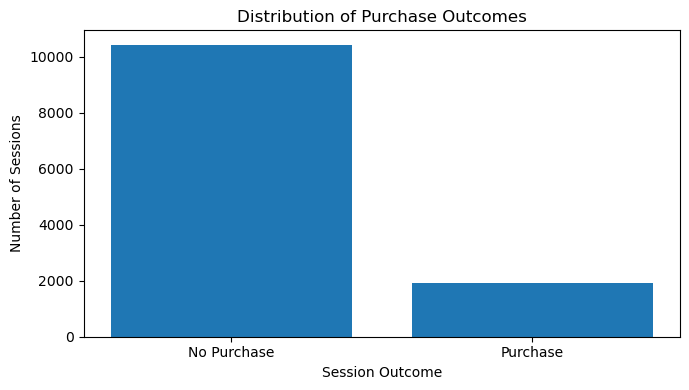

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.bar(
    target_summary["Session Outcome"],
    target_summary["Count"]
)

plt.title("Distribution of Purchase Outcomes")
plt.xlabel("Session Outcome")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()

In [6]:
majority_class_accuracy = (
    df_raw["Revenue"].value_counts(normalize=True).max() * 100
)

print(f"Majority-class baseline accuracy: {majority_class_accuracy:.2f}%")

Majority-class baseline accuracy: 84.53%


### 2.2 Interpretation of Target Distribution

The target variable `Revenue` exhibits a noticeable class imbalance.

| Session Outcome | Count | Percentage |
|---|---:|---:|
| No Purchase (`False`) | 10,422 | 84.53% |
| Purchase (`True`) | 1,908 | 15.47% |
| **Total** | **12,330** | **100.00%** |

The majority class is `False`, representing sessions that did not result in a purchase. A naive classifier that predicts no purchase for every session would achieve a baseline accuracy of 84.53%.

This baseline demonstrates why accuracy should not be used as the sole evaluation metric. A model could achieve apparently high accuracy while failing to identify a substantial proportion of actual purchases. Therefore, precision, recall, F1-score, ROC-AUC, and Matthews Correlation Coefficient (MCC) will also be considered when comparing the classification models.

**Conclusion:** The class imbalance must be considered during model evaluation. Stratified train-test splitting will be used to preserve the approximate class proportions in both datasets.

In [7]:
numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

display(
    df_raw[numerical_features]
    .describe()
    .T
    .round(3)
)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315,3.322,0.0,0.000,1.000,4.000,27.000
Administrative_Duration,12330.0,80.819,176.779,0.0,0.000,7.500,93.256,3398.750
Informational,12330.0,0.504,1.270,0.0,0.000,0.000,0.000,24.000
Informational_Duration,12330.0,34.472,140.749,0.0,0.000,0.000,0.000,2549.375
ProductRelated,12330.0,31.731,44.476,0.0,7.000,18.000,38.000,705.000
ProductRelated_Duration,12330.0,1194.746,1913.669,0.0,184.138,598.937,1464.157,63973.522
BounceRates,12330.0,0.022,0.048,0.0,0.000,0.003,0.017,0.200
ExitRates,12330.0,0.043,0.049,0.0,0.014,0.025,0.050,0.200
PageValues,12330.0,5.889,18.568,0.0,0.000,0.000,0.000,361.764
SpecialDay,12330.0,0.061,0.199,0.0,0.000,0.000,0.000,1.000


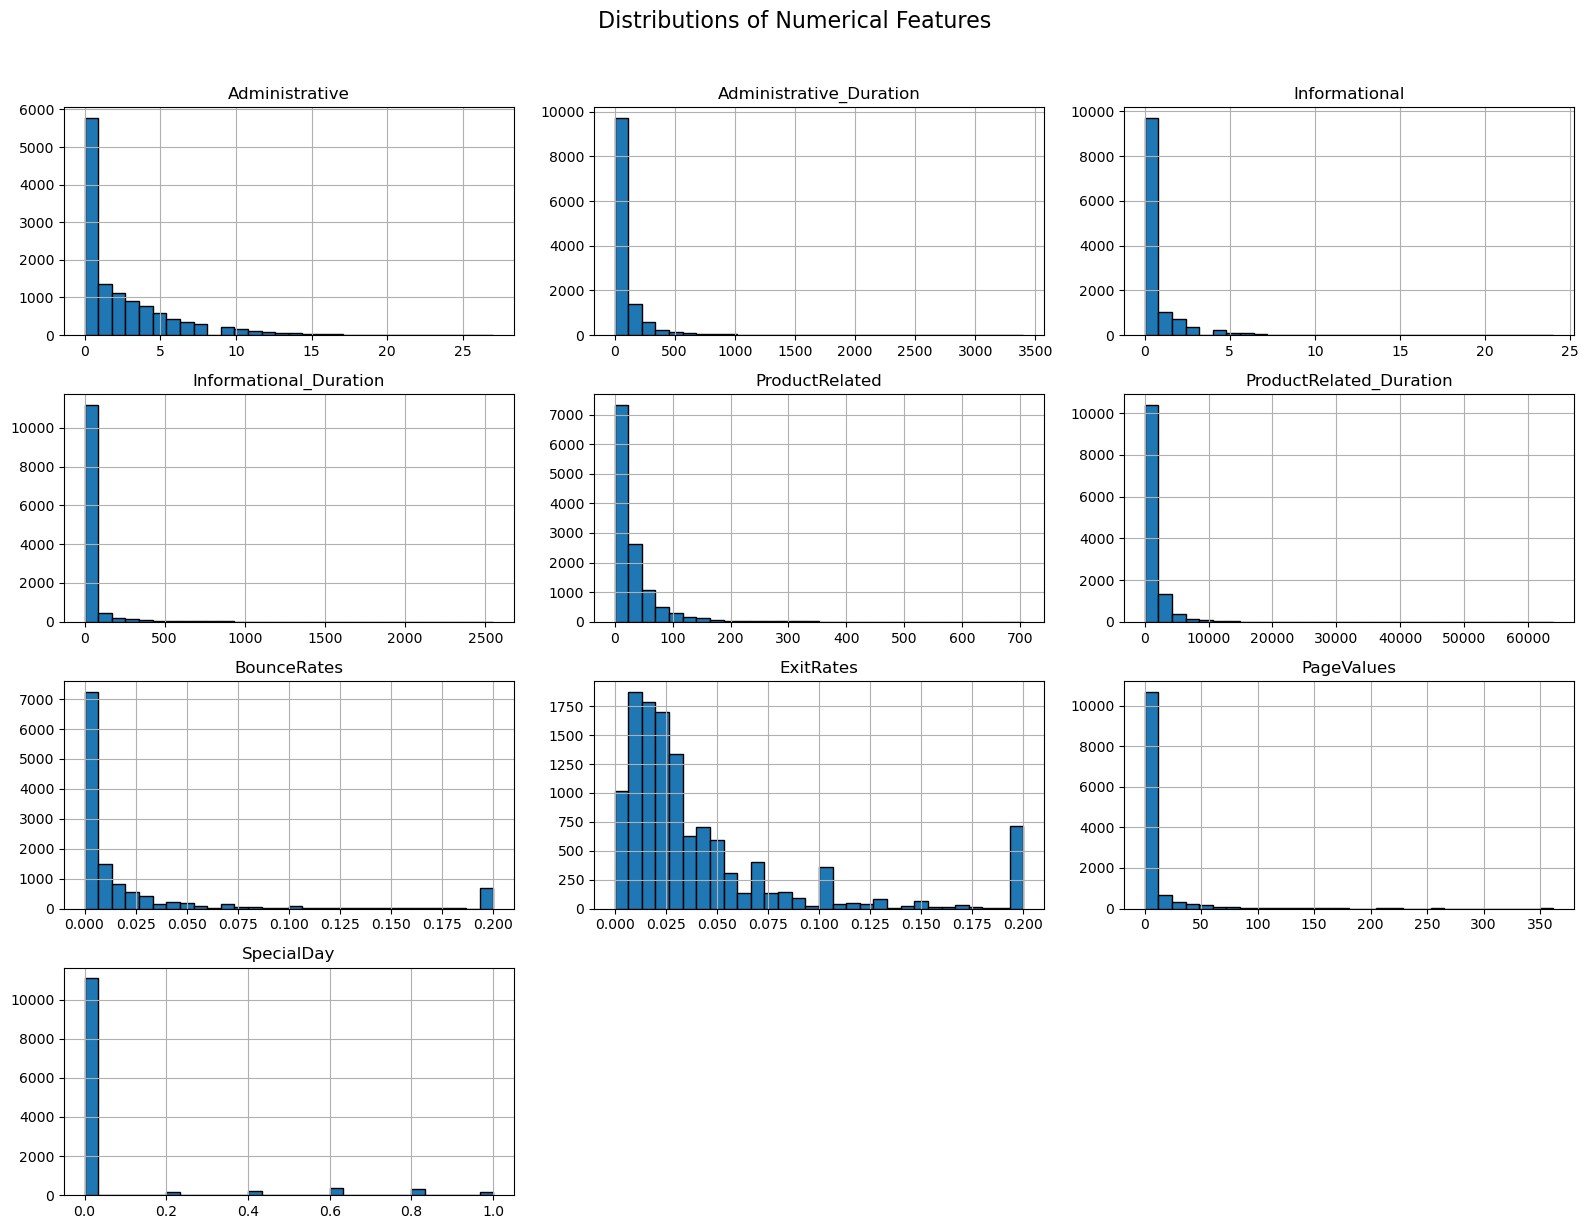

In [8]:
df_raw[numerical_features].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distributions of Numerical Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

In [9]:
feature_analysis = pd.DataFrame({
    "Skewness": df_raw[numerical_features].skew(),
    "Zero Count": (df_raw[numerical_features] == 0).sum(),
    "Zero Percentage": (
        (df_raw[numerical_features] == 0).mean() * 100
    ).round(2)
})

display(feature_analysis.round(3))

,Skewness,Zero Count,Zero Percentage
Administrative,1.960,5768,46.78
Administrative_Duration,5.616,5903,47.88
Informational,4.036,9699,78.66
Informational_Duration,7.579,9925,80.49
ProductRelated,4.342,38,0.31
ProductRelated_Duration,7.263,755,6.12
BounceRates,2.948,5518,44.75
ExitRates,2.149,76,0.62
PageValues,6.383,9600,77.86
SpecialDay,3.303,11079,89.85


### 2.3 Numerical Feature Distribution Analysis

Descriptive statistics, histograms, skewness, and zero-value percentages were examined for the ten numerical features.

The analysis revealed that several features are positively skewed, particularly `Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration`, and `PageValues`. This indicates that a relatively small number of observations have much larger values than the majority.

Several features also contain a high proportion of zero values. For example, `Informational_Duration` has 80.49% zero values, `PageValues` has 77.86%, and `SpecialDay` has 89.85%. These zeros may represent genuine session characteristics and should not automatically be treated as missing data.

These findings suggest that feature scaling will be important to evaluate for Logistic Regression, KNN, and SVM. Any additional transformations will be considered only after examining their potential benefits. The original feature values will be retained unless there is a clear analytical reason to modify them.

**Conclusion:** The numerical features have different distributions and scales. These characteristics must be considered when selecting preprocessing methods and comparing model performance.

In [10]:
revenue_comparison = (
    df_raw.groupby("Revenue")[numerical_features]
    .mean()
    .T
    .rename(columns={
        False: "No Purchase",
        True: "Purchase"
    })
)

display(revenue_comparison.round(3))

Revenue,No Purchase,Purchase
Administrative,2.118,3.394
Administrative_Duration,73.740,119.483
Informational,0.452,0.786
Informational_Duration,30.236,57.611
ProductRelated,28.715,48.210
ProductRelated_Duration,1069.988,1876.210
BounceRates,0.025,0.005
ExitRates,0.047,0.020
PageValues,1.976,27.265
SpecialDay,0.068,0.023


### 2.4 Numerical Features by Purchase Outcome

The mean values of the numerical features were compared between sessions resulting in a purchase and sessions that did not result in a purchase.

The comparison shows that purchasing sessions have higher average values for `Administrative`, `Informational`, `ProductRelated`, and their corresponding duration features. In contrast, `BounceRates` and `ExitRates` have lower average values for purchasing sessions.

The mean `PageValues` is substantially higher for purchasing sessions (27.265) than for non-purchasing sessions (1.976). This feature may contain useful predictive information, but its definition and availability at prediction time must be investigated to assess potential data leakage.

The mean `SpecialDay` is lower for purchasing sessions in this dataset. These comparisons are descriptive and do not establish causation or statistical significance.

**Conclusion:** Several browsing-behavior features show differences between the two target groups. Further analysis and careful feature selection are necessary before model training.

In [11]:
categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

for feature in categorical_features:
    print(f"\n{'=' * 50}")
    print(f"Feature: {feature}")
    print(df_raw[feature].value_counts(dropna=False))


Feature: Month
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

Feature: OperatingSystems
OperatingSystems
2    6601
1    2585
3    2555
4     478
8      79
6      19
7       7
5       6
Name: count, dtype: int64

Feature: Browser
Browser
2     7961
1     2462
4      736
5      467
6      174
10     163
8      135
3      105
13      61
7       49
12      10
11       6
9        1
Name: count, dtype: int64

Feature: Region
Region
1    4780
3    2403
4    1182
2    1136
6     805
7     761
9     511
8     434
5     318
Name: count, dtype: int64

Feature: TrafficType
TrafficType
2     3913
1     2451
3     2052
4     1069
13     738
10     450
6      444
8      343
5      260
11     247
20     198
9       42
7       40
15      38
19      17
14      13
18      10
16       3
12       1
17       1
Name: count, dtype: int64

Feature: VisitorType
VisitorType
Returning_Visitor    10

In [12]:
for feature in categorical_features:
    print(f"\nPurchase rate by {feature}:")

    purchase_rates = (
        df_raw.groupby(feature, observed=True)["Revenue"]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "Session Count",
            "mean": "Purchase Rate"
        })
    )

    purchase_rates["Purchase Rate"] *= 100

    display(purchase_rates.round(2))


Purchase rate by Month:


,Session Count,Purchase Rate
Month,,
Aug,433,17.55
Dec,1727,12.51
Feb,184,1.63
Jul,432,15.28
June,288,10.07
Mar,1907,10.07
May,3364,10.85
Nov,2998,25.35
Oct,549,20.95



Purchase rate by OperatingSystems:


,Session Count,Purchase Rate
OperatingSystems,,
1,2585,14.66
2,6601,17.50
3,2555,10.49
4,478,17.78
5,6,16.67
6,19,10.53
7,7,14.29
8,79,21.52



Purchase rate by Browser:


,Session Count,Purchase Rate
Browser,,
1,2462,14.83
2,7961,15.36
3,105,4.76
4,736,17.66
5,467,18.42
6,174,11.49
7,49,12.24
8,135,15.56
9,1,0.00


... (4 outputs left out)


Purchase rate by VisitorType:


,Session Count,Purchase Rate
VisitorType,,
New_Visitor,1694,24.91
Other,85,18.82
Returning_Visitor,10551,13.93



Purchase rate by Weekend:


,Session Count,Purchase Rate
Weekend,,
False,9462,14.89
True,2868,17.40


### 2.5 Categorical Feature Analysis

The purchase rates of the categorical and integer-coded features were examined to understand how purchase outcomes vary across their categories.

The analysis showed that purchase rates differ across months, operating systems, browsers, regions, traffic types, visitor types, and weekend status. November had the highest purchase rate among the observed months (25.35%), while February had the lowest (1.63%). New visitors had a higher purchase rate (24.91%) than returning visitors (13.93%). Weekend sessions also had a slightly higher purchase rate (17.40%) than weekday sessions (14.89%).

Some categories had very small sample sizes. For example, TrafficType 16 contained only three sessions, and Browser 9 contained one session. Their observed purchase rates should therefore be interpreted cautiously.

The integer-coded features represent categories rather than necessarily meaningful numerical quantities. Their encoding will be chosen to avoid imposing an artificial numerical order on the category labels.

**Conclusion:** Categorical features exhibit variation in purchase rates and may provide useful predictive information. These observations are exploratory and do not establish causation or statistical significance.

In [13]:
for outcome, group in df_raw.groupby("Revenue"):
    label = "Purchase" if outcome else "No Purchase"

    print(f"\n{label}")
    print(
        group["PageValues"]
        .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
        .round(3)
    )


No Purchase
count    10422.000
mean         1.976
std          9.072
min          0.000
25%          0.000
50%          0.000
75%          0.000
90%          2.688
95%         12.581
99%         41.873
max        246.759
Name: PageValues, dtype: float64

Purchase
count    1908.000
mean       27.265
std        35.192
min         0.000
25%         3.641
50%        16.758
75%        38.898
90%        63.606
95%        88.798
99%       154.059
max       361.764
Name: PageValues, dtype: float64


### 2.6 Investigation of PageValues and Potential Data Leakage

The distribution of `PageValues` was examined separately for purchase and non-purchase sessions.

The mean `PageValues` was 27.265 for purchase sessions and 1.976 for non-purchase sessions. The median was 16.758 for purchase sessions and 0 for non-purchase sessions, indicating a substantial difference between the two groups.

According to the UCI dataset documentation, `PageValues` represents the average value associated with pages visited before an e-commerce transaction is completed. Its relationship with the target therefore warrants careful investigation.

If the intended application predicts purchase intention before a transaction occurs, this feature may introduce information that would not be available at prediction time. Its predictive usefulness alone is not sufficient justification for including it.

To assess its influence, two experimental settings will be compared: one using all 17 input features and another excluding `PageValues`. The results will be interpreted in the context of the intended prediction scenario.

**Conclusion:** `PageValues` will be investigated through a comparative experiment rather than being automatically retained or removed.

### 2.7 Overall EDA Summary

The exploratory data analysis identified the following characteristics:

1. The dataset contains 12,330 sessions, 17 input features, and a binary target variable, `Revenue`.
2. No missing values were found during the initial inspection.
3. The target is imbalanced: 84.53% of sessions did not result in a purchase, while 15.47% resulted in a purchase.
4. Several numerical features are strongly right-skewed and contain many zero values. These values will not automatically be treated as missing data.
5. Purchase rates vary across categorical features, including month, visitor type, traffic type, and weekend status. Categories with small sample sizes require cautious interpretation.
6. Purchasing sessions have higher average product-related browsing activity and lower average bounce and exit rates in this dataset.
7. `PageValues` differs substantially between purchase and non-purchase sessions and requires investigation for potential data leakage.
8. Feature scaling and categorical encoding will be considered when building the preprocessing pipelines for the five classification algorithms.

**Conclusion:** The dataset is suitable for the intended classification task. The next stage is to establish a reproducible train-test split and construct preprocessing pipelines, ensuring that preprocessing is fitted only on training data to avoid data leakage.

## Step 3: Train-Test Split and Preprocessing

### 3.1 Defining the Prediction Setup

The objective is to predict whether an online shopping session results in a purchase using the session's available features.

The target variable is `Revenue`, and the remaining columns are candidate input features. The dataset will be divided into training and testing subsets using an 80:20 ratio.

Stratified splitting will be used to preserve the approximate proportion of purchase and non-purchase sessions in both subsets. A fixed random state will make the split reproducible.

Preprocessing operations will be fitted using only the training data and then applied to the test data. This prevents information from the test set from influencing the preprocessing stage.

Two feature configurations will eventually be compared: one using all 17 features and another excluding `PageValues` to investigate its potential impact on model performance.

In [14]:
# 3.2 Separate features and target
X = df_raw.drop(columns=["Revenue"]).copy()
y = df_raw["Revenue"].astype(int).copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("\nTarget class counts:")
print(y.value_counts().sort_index())

Feature matrix shape: (12330, 17)
Target vector shape: (12330,)

Target class counts:
Revenue
0    10422
1     1908
Name: count, dtype: int64


In [15]:
#3.3 Create the stratified split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))

Training features: (9864, 17)
Testing features: (2466, 17)

Training target distribution:
Revenue
0    8338
1    1526
Name: count, dtype: int64
Revenue
0    84.53
1    15.47
Name: proportion, dtype: float64

Testing target distribution:
Revenue
0    2084
1     382
Name: count, dtype: int64
Revenue
0    84.51
1    15.49
Name: proportion, dtype: float64


### 3.2 Train-Test Split Results

The dataset was divided into training and testing subsets using an 80:20 ratio. Stratified sampling was performed with `random_state=42` to preserve reproducibility and the target-class proportions.

- Training set: 9,864 records and 17 input features.
- Test set: 2,466 records and 17 input features.
- Training purchase rate: 15.47%.
- Test purchase rate: 15.49%.

The purchase proportions in the two subsets are nearly identical to the original dataset proportion of 15.47%. This confirms that stratification has preserved the class distribution appropriately.

**Conclusion:** The data split is complete. The test set will be kept separate from model fitting and preprocessing decisions to support a fair evaluation of model generalization.

In [16]:
#3.5 Design the preprocessing pipeline
continuous_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

categorical_features = [
    "Month",
    "VisitorType",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

boolean_features = ["Weekend"]

print("Continuous numerical features:", len(continuous_features))
print("Categorical features:", len(categorical_features))
print("Boolean features:", len(boolean_features))

print(
    "\nTotal:",
    len(continuous_features)
    + len(categorical_features)
    + len(boolean_features)
)

Continuous numerical features: 10
Categorical features: 6
Boolean features: 1

Total: 17


In [17]:
# Use standard scalar for numericals, onehot encoder for categorical and convert booleans to 0 and 1
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

numeric_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, continuous_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("boolean", "passthrough", boolean_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [18]:
# 3.6 Fit and verify the preprocessing pipeline
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Transformed training shape:", X_train_processed.shape)

print("\nOriginal test shape:", X_test.shape)
print("Transformed test shape:", X_test_processed.shape)

print("\nTraining data contains NaN:",
      np.isnan(X_train_processed.toarray()
               if hasattr(X_train_processed, "toarray")
               else X_train_processed).any())

print("Test data contains NaN:",
      np.isnan(X_test_processed.toarray()
               if hasattr(X_test_processed, "toarray")
               else X_test_processed).any())

Original training shape: (9864, 17)
Transformed training shape: (9864, 74)

Original test shape: (2466, 17)
Transformed test shape: (2466, 74)

Training data contains NaN: False
Test data contains NaN: False


### 3.3 Preprocessing Pipeline Verification

The preprocessing transformer was fitted using the training dataset and then applied to the test dataset.

The original 17 input features were transformed into 74 features after one-hot encoding the categorical variables. The continuous numerical features were standardized, while the Boolean feature was passed through unchanged.

The transformed training matrix has 9,864 rows and 74 columns, and the transformed test matrix has 2,466 rows and 74 columns. No missing values were detected in either transformed matrix.

**Conclusion:** The preprocessing transformer is functioning as expected. For model training and deployment, preprocessing will be integrated into each classifier's pipeline so that the same transformations are applied consistently to new data.

In [19]:
transformed_feature_names = preprocessor.get_feature_names_out()

print("Number of transformed features:",
      len(transformed_feature_names))

print("\nFirst 30 transformed feature names:")
print(transformed_feature_names[:30])

Number of transformed features: 74

First 30 transformed feature names:
['numeric__Administrative' 'numeric__Administrative_Duration'
 'numeric__Informational' 'numeric__Informational_Duration'
 'numeric__ProductRelated' 'numeric__ProductRelated_Duration'
 'numeric__BounceRates' 'numeric__ExitRates' 'numeric__PageValues'
 'numeric__SpecialDay' 'categorical__Month_Aug' 'categorical__Month_Dec'
 'categorical__Month_Feb' 'categorical__Month_Jul'
 'categorical__Month_June' 'categorical__Month_Mar'
 'categorical__Month_May' 'categorical__Month_Nov'
 'categorical__Month_Oct' 'categorical__Month_Sep'
 'categorical__VisitorType_New_Visitor' 'categorical__VisitorType_Other'
 'categorical__VisitorType_Returning_Visitor'
 'categorical__OperatingSystems_1' 'categorical__OperatingSystems_2'
 'categorical__OperatingSystems_3' 'categorical__OperatingSystems_4'
 'categorical__OperatingSystems_5' 'categorical__OperatingSystems_6'
 'categorical__OperatingSystems_7']


### 3.4 Verification of Transformed Feature Names

The transformed feature names were inspected to verify the preprocessing output. The transformer generated 74 features from the original 17 input features.

The continuous numerical features retained their individual columns after standardization. The categorical features were expanded into indicator columns using one-hot encoding. The Boolean feature `Weekend` was passed through unchanged.

The feature names also confirm that the categorical variables are distinguished using prefixes identifying their preprocessing groups.

**Conclusion:** The transformed feature matrix has the expected structure and can be used within the classification pipelines.

## Step 4: Classification Model Development

Five classification algorithms will be implemented and evaluated using the same training and testing subsets. Each classifier will be integrated with the preprocessing transformer in a single pipeline.

This approach ensures that preprocessing is fitted using training data and applied consistently during prediction. It also allows each complete pipeline to be saved and reused by the Streamlit application.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.pipeline import Pipeline

print("All five classification algorithms imported successfully.")

All five classification algorithms imported successfully.


In [21]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "Gaussian Naive Bayes": GaussianNB(),
    "SVM": SVC(
        probability=True,
        random_state=42
    )
}

print("Models configured:")
for name, model in models.items():
    print(f"- {name}: {model.__class__.__name__}")

Models configured:
- Logistic Regression: LogisticRegression
- Decision Tree: DecisionTreeClassifier
- KNN: KNeighborsClassifier
- Gaussian Naive Bayes: GaussianNB
- SVM: SVC


In [22]:
# Configure pipelines
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone

numeric_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, continuous_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("boolean", "passthrough", boolean_features)
    ],
    remainder="drop"
)

In [23]:
model_pipelines = {}

for model_name, model in models.items():
    model_pipelines[model_name] = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(model))
    ])

print(f"Configured {len(model_pipelines)} model pipelines.")

for model_name in model_pipelines:
    print("-", model_name)

Configured 5 model pipelines.
- Logistic Regression
- Decision Tree
- KNN
- Gaussian Naive Bayes
- SVM


In [24]:
# Train Models Independntly
import time

training_results = {}

for model_name, pipeline in model_pipelines.items():
    start_time = time.time()

    pipeline.fit(X_train, y_train)

    training_time = time.time() - start_time

    training_results[model_name] = {
        "pipeline": pipeline,
        "training_time_seconds": round(training_time, 2)
    }

    print(
        f"{model_name}: trained successfully "
        f"in {training_time:.2f} seconds"
    )

Logistic Regression: trained successfully in 60.58 seconds
Decision Tree: trained successfully in 0.42 seconds
KNN: trained successfully in 0.03 seconds
Gaussian Naive Bayes: trained successfully in 0.08 seconds
SVM: trained successfully in 29.62 seconds


In [25]:
print("Training verification:")
print("-" * 35)

for model_name, result in training_results.items():
    print(
        f"{model_name}: "
        f"{'Trained' if hasattr(result['pipeline'].named_steps['classifier'], 'classes_') else 'Not trained'}"
    )

Training verification:
-----------------------------------
Logistic Regression: Trained
Decision Tree: Trained
KNN: Trained
Gaussian Naive Bayes: Trained
SVM: Trained


In [26]:
# 5.1 Calculate the metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix
)
import pandas as pd

evaluation_results = []
confusion_matrices = {}

for model_name, result in training_results.items():
    pipeline = result["pipeline"]

    # Predict class labels
    y_pred = pipeline.predict(X_test)

    # Obtain continuous scores for AUC
    if hasattr(pipeline, "predict_proba"):
        y_score = pipeline.predict_proba(X_test)[:, 1]
    else:
        y_score = pipeline.decision_function(X_test)

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "Training Time (s)": result["training_time_seconds"]
    })

    confusion_matrices[model_name] = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df = evaluation_df.sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

evaluation_df.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1-score,MCC,Training Time (s)
0,SVM,0.8873,0.8817,0.7063,0.4660,0.5615,0.5142,29.62
1,Decision Tree,0.8593,0.7340,0.5452,0.5524,0.5488,0.4654,0.42
2,Logistic Regression,0.8812,0.8830,0.7405,0.3586,0.4832,0.4610,60.58
3,KNN,0.8715,0.7572,0.6419,0.3848,0.4812,0.4307,0.03
4,Gaussian Naive Bayes,0.2733,0.7328,0.1727,0.9738,0.2934,0.1292,0.08


In [27]:
# 5.2 Display the confusion matrices
for model_name, matrix in confusion_matrices.items():
    print(f"\n{model_name}")
    print("Rows = Actual, Columns = Predicted")
    print(matrix)


Logistic Regression
Rows = Actual, Columns = Predicted
[[2036   48]
 [ 245  137]]

Decision Tree
Rows = Actual, Columns = Predicted
[[1908  176]
 [ 171  211]]

KNN
Rows = Actual, Columns = Predicted
[[2002   82]
 [ 235  147]]

Gaussian Naive Bayes
Rows = Actual, Columns = Predicted
[[ 302 1782]
 [  10  372]]

SVM
Rows = Actual, Columns = Predicted
[[2010   74]
 [ 204  178]]


In [28]:
display(
    evaluation_df.set_index("Model").round(4)
)

,Accuracy,AUC,Precision,Recall,F1-score,MCC,Training Time (s)
Model,,,,,,,
SVM,0.8873,0.8817,0.7063,0.4660,0.5615,0.5142,29.62
Decision Tree,0.8593,0.7340,0.5452,0.5524,0.5488,0.4654,0.42
Logistic Regression,0.8812,0.8830,0.7405,0.3586,0.4832,0.4610,60.58
KNN,0.8715,0.7572,0.6419,0.3848,0.4812,0.4307,0.03
Gaussian Naive Bayes,0.2733,0.7328,0.1727,0.9738,0.2934,0.1292,0.08


### Interpretation of Baseline Model Results

Among the five baseline models, SVM achieved the highest accuracy (88.73%), F1-score (0.5615), and MCC (0.5142), indicating the strongest overall classification performance in this experiment. Logistic Regression achieved the highest AUC (0.8830) and precision (0.7405), while Decision Tree obtained higher recall (0.5524) than the other models except Gaussian Naive Bayes. Gaussian Naive Bayes achieved the highest recall (0.9738) but had very low precision and accuracy due to a large number of false-positive predictions. Overall, SVM appears to provide the best balance of performance across the evaluated metrics, although further experiments are needed before selecting the final model.

### SVM Kernel Comparison – Motivation

In the baseline evaluation, Support Vector Machine (SVM) achieved the highest accuracy (88.73%), F1-score (0.5615), and MCC (0.5142) among the five classification models. However, its performance may depend on the choice of kernel function, which determines how the model identifies decision boundaries between different classes.

To investigate whether the baseline SVM performance can be improved, we will experiment with different kernel functions while keeping the training and testing datasets and preprocessing approach unchanged.

The objective is to identify a suitable kernel that provides a better balance between precision, recall, F1-score, AUC, and MCC, particularly considering the imbalance in the target variable.

### Different Kernel Functions in SVM

SVM uses kernel functions to identify decision boundaries between classes. Different kernels allow the algorithm to learn different types of relationships in the feature space.

The following three kernels are considered in this experiment:

1. **Linear Kernel**
   - Creates a linear decision boundary between classes.
   - Suitable when the classes can be reasonably separated using a linear relationship.
   - Generally simpler and computationally less expensive than nonlinear kernels.

2. **Radial Basis Function (RBF) Kernel**
   - Creates nonlinear decision boundaries.
   - Uses the similarity between observations to capture complex patterns.
   - Suitable when the relationship between features and target classes is nonlinear.

3. **Polynomial Kernel**
   - Captures polynomial relationships between features.
   - Can model interactions and more complex decision boundaries.
   - Its behaviour depends on parameters such as polynomial degree.

By comparing these kernels, we aim to understand how different decision boundaries influence the classification performance on the Online Shoppers Purchasing Intention dataset.

In [29]:
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)
import pandas as pd
import time

# Define SVM variants
svm_kernels = {
    "SVM Linear": SVC(
        kernel="linear",
        random_state=42
    ),

    "SVM RBF": SVC(
        kernel="rbf",
        random_state=42
    ),

    "SVM Polynomial": SVC(
        kernel="poly",
        degree=3,
        random_state=42
    )
}

svm_kernel_results = []
svm_kernel_pipelines = {}

# Train and evaluate each SVM variant
for model_name, svm_model in svm_kernels.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", svm_model)
    ])

    start_time = time.time()

    pipeline.fit(X_train, y_train)

    training_time = time.time() - start_time

    y_pred = pipeline.predict(X_test)
    y_score = pipeline.decision_function(X_test)

    svm_kernel_pipelines[model_name] = pipeline

    svm_kernel_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "Training Time (s)": round(training_time, 2)
    })

svm_kernel_df = pd.DataFrame(svm_kernel_results)

svm_kernel_df.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1-score,MCC,Training Time (s)
0,SVM Linear,0.8820,0.8880,0.7358,0.3717,0.4939,0.4678,10.62
1,SVM RBF,0.8873,0.8817,0.7063,0.4660,0.5615,0.5142,5.07
2,SVM Polynomial,0.8804,0.8534,0.7122,0.3822,0.4974,0.4638,6.30


### SVM Kernel Comparison – Results and Observations

The experimental results indicate that the RBF kernel provides the strongest overall classification performance, achieving an accuracy of 88.73%, F1-score of 0.5615, and MCC of 0.5142. It also achieves the highest recall (0.4660) among the three kernels.

The Linear kernel achieves the highest AUC (0.8880) and precision (0.7358), indicating better class-ranking performance and fewer false-positive predictions at the default threshold. However, its lower recall results in a comparatively lower F1-score.

The Polynomial kernel does not outperform the other two kernels across the evaluated metrics.

Based on the overall balance between precision, recall, F1-score, and MCC, the RBF kernel is selected as the preferred SVM configuration for further experimentation.

### SVM Hyperparameter Tuning – Motivation

From the SVM kernel comparison, the RBF kernel demonstrated the strongest overall classification performance, achieving an F1-score of 0.5615 and an MCC of 0.5142.

However, the performance of an SVM model is influenced not only by its kernel function but also by its hyperparameters. The default parameter values may not provide the most suitable decision boundary for the given dataset.

Therefore, we will perform hyperparameter tuning on the selected RBF kernel using RandomizedSearchCV with Stratified 3-Fold Cross-Validation.

The objective is to identify a suitable combination of hyperparameters that improves the model's classification performance while maintaining its ability to generalize to unseen data.

In [32]:
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)
from scipy.stats import loguniform

# Create the RBF SVM pipeline
svm_rbf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", SVC(
        kernel="rbf",
        random_state=42
    ))
])

# Define parameter search space
param_distributions = {
    "classifier__C": loguniform(0.01, 100),
    "classifier__gamma": loguniform(0.0001, 1),
    "classifier__class_weight": [None, "balanced"]
}

# Stratified cross-validation
stratified_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Configure randomized search
svm_random_search = RandomizedSearchCV(
    estimator=svm_rbf_pipeline,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="f1",
    cv=stratified_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("SVM hyperparameter search configured.")

SVM hyperparameter search configured.


In [33]:
import time

start_time = time.time()

svm_random_search.fit(X_train, y_train)

search_duration = time.time() - start_time

print("Hyperparameter search completed.")
print(f"Execution time: {search_duration:.2f} seconds")

print("\nBest parameters:")
print(svm_random_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(svm_random_search.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Hyperparameter search completed.
Execution time: 197.60 seconds

Best parameters:
{'classifier__C': 56.78201970293117, 'classifier__class_weight': 'balanced', 'classifier__gamma': 0.000533703276260396}

Best cross-validation F1-score:
0.6514


### SVM Hyperparameter Tuning – Results

RandomizedSearchCV evaluated 12 hyperparameter combinations using Stratified 3-Fold Cross-Validation, resulting in 36 model fits.

The best-performing configuration was identified with the following parameters:

- C: 56.7820
- Gamma: 0.000534
- Class Weight: Balanced

The selected configuration achieved a mean cross-validation F1-score of 0.6514. This indicates an improvement in the model's ability to balance precision and recall during cross-validation compared with the baseline RBF SVM.

The use of balanced class weights may help the model account for the imbalance between purchase and non-purchase sessions.

The selected configuration will now be evaluated on the independent test dataset to determine whether the improvement generalizes to unseen observations.

In [34]:
# Retrieve the best tuned pipeline
best_svm_model = svm_random_search.best_estimator_

# Predict on the untouched test dataset
y_pred_tuned = best_svm_model.predict(X_test)

# Obtain decision scores for AUC
y_score_tuned = best_svm_model.decision_function(X_test)

# Calculate evaluation metrics
tuned_svm_metrics = {
    "Model": "Tuned SVM (RBF)",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "AUC": roc_auc_score(y_test, y_score_tuned),
    "Precision": precision_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    "MCC": matthews_corrcoef(y_test, y_pred_tuned)
}

pd.DataFrame([tuned_svm_metrics]).round(4)

,Model,Accuracy,AUC,Precision,Recall,F1-score,MCC
0,Tuned SVM (RBF),0.871,0.9028,0.5637,0.7408,0.6403,0.5713


In [35]:
svm_comparison = pd.DataFrame([
    {
        "Model": "Baseline SVM (RBF)",
        "Accuracy": 0.8873,
        "AUC": 0.8817,
        "Precision": 0.7063,
        "Recall": 0.4660,
        "F1-score": 0.5615,
        "MCC": 0.5142
    },
    tuned_svm_metrics
])

svm_comparison.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1-score,MCC
0,Baseline SVM (RBF),0.8873,0.8817,0.7063,0.4660,0.5615,0.5142
1,Tuned SVM (RBF),0.8710,0.9028,0.5637,0.7408,0.6403,0.5713


### Decision Threshold Analysis

The default SVM decision threshold determines whether a session is classified as a purchase or non-purchase. However, this threshold may not provide the best balance between precision and recall for an imbalanced dataset.

In this experiment:
- Split the existing training data into training and validation subsets using stratification.
- Train an SVM using the best hyperparameters identified through RandomizedSearchCV.
- Generate decision scores for the validation set.
- Evaluate different classification thresholds using Precision, Recall and F1-score.
- Select a threshold based on validation performance and evaluate it once on the untouched test set.

The primary objective is to improve the balance between precision and recall, measured using F1-score.

In [37]:
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Sub-training shape:", X_subtrain.shape)
print("Validation shape:", X_val.shape)

print("\nValidation class distribution:")
print(y_val.value_counts(normalize=True))

Sub-training shape: (7891, 17)
Validation shape: (1973, 17)

Validation class distribution:
Revenue
0    0.845413
1    0.154587
Name: proportion, dtype: float64


In [38]:
from sklearn.base import clone

threshold_svm = clone(svm_random_search.best_estimator_)

threshold_svm.fit(X_subtrain, y_subtrain)

# SVM decision scores for validation data
val_scores = threshold_svm.decision_function(X_val)

print("Validation predictions generated.")

Validation predictions generated.


In [39]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(-1.0, 1.01, 0.05)

threshold_results = []

for threshold in thresholds:
    val_predictions = (val_scores >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.sort_values(
    by="F1", ascending=False
).head(10)

,Threshold,Precision,Recall,F1
26,3.000000e-01,0.622905,0.731148,0.672700
27,3.500000e-01,0.626781,0.721311,0.670732
25,2.500000e-01,0.612466,0.740984,0.670623
28,4.000000e-01,0.633431,0.708197,0.668731
19,-5.000000e-02,0.564920,0.813115,0.666667
17,-1.500000e-01,0.551948,0.836066,0.664928
20,8.881784e-16,0.572104,0.793443,0.664835
18,-1.000000e-01,0.556541,0.822951,0.664021
22,1.000000e-01,0.585000,0.767213,0.663830
24,2.000000e-01,0.597884,0.740984,0.661786


### Final Evaluation of SVM with Optimized Decision Threshold

The threshold of 0.30 was selected based on validation F1-score. The selected threshold is now evaluated on the independent test dataset to assess its generalization performance.

The test dataset has not been used for model training or threshold selection.

In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

selected_threshold = 0.30

test_scores = threshold_svm.decision_function(X_test)

test_predictions = (
    test_scores >= selected_threshold
).astype(int)

threshold_test_results = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "AUC": roc_auc_score(y_test, test_scores),
    "Precision": precision_score(y_test, test_predictions),
    "Recall": recall_score(y_test, test_predictions),
    "F1": f1_score(y_test, test_predictions),
    "MCC": matthews_corrcoef(y_test, test_predictions)
}

print("Test Metrics at Threshold:", selected_threshold)
print(pd.Series(threshold_test_results).round(4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions))

Test Metrics at Threshold: 0.3
Accuracy     0.8792
AUC          0.9043
Precision    0.5968
Recall       0.6780
F1           0.6348
MCC          0.5644
dtype: float64

Confusion Matrix:
[[1909  175]
 [ 123  259]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      2084
           1       0.60      0.68      0.63       382

    accuracy                           0.88      2466
   macro avg       0.77      0.80      0.78      2466
weighted avg       0.89      0.88      0.88      2466



### Conclusion – SVM Decision Threshold Analysis

The decision threshold experiment was conducted to investigate the trade-off between precision and recall for the tuned RBF SVM.

A threshold of 0.30 achieved the best validation F1-score of 0.6727, with precision of 0.6229 and recall of 0.7311.

On the independent test set, the model achieved:
- Accuracy: 87.92%
- AUC: 90.43%
- Precision: 59.68%
- Recall: 67.80%
- F1-score: 63.48%
- MCC: 56.44%

The experiment demonstrated that threshold selection can influence the balance between identifying actual purchasers and reducing false purchase predictions.

Although the selected threshold improved precision compared with the default threshold used in this experiment, its test F1-score was slightly lower than that of the previously tuned SVM. Therefore, the tuned RBF SVM with its default decision threshold is retained as the primary improved model, while threshold 0.30 is considered an alternative when a more selective prediction strategy is preferred.